# J1 — Réseau de neurones de base

Objectif : construire et vérifier un réseau `2 → 16 → 8 → 1` en NumPy, avant d’implémenter les optimiseurs.

## Suivi des travaux demandés
- [x] A1 — données, visualisation, split et standardisation
- [x] B1 — forward et binary cross-entropy
- [x] B2 — rétropropagation
- [x] Vérification numérique des gradients
- [x] Validation J1 : dimensions, loss finie, gradients corrects, loss qui diminue sur un petit jeu

Le notebook documente les travaux demandés et appelle les fonctions des modules Python. Nous complétons les modules progressivement, jalon par jalon.


## A1 — Données et préparation
Générer `make_moons` avec 1 500 observations et bruit 0,20. Faire un split stratifié 60/20/20. Calculer moyenne et écart-type sur le train uniquement, puis utiliser ces statistiques pour transformer les trois ensembles.


Données complètes — X : (1500, 2), y : (1500,)
Effectifs par classe : {0: 750, 1: 750}


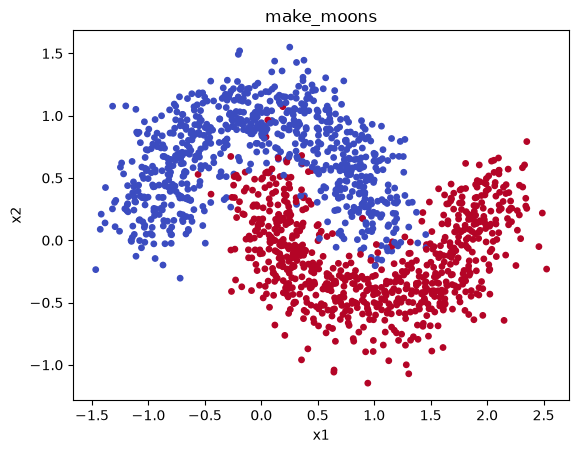

Train standardisé — X : (900, 2), y : (900, 1)
Effectifs par classe : {0: 450, 1: 450}
Validation standardisée — X : (300, 2), y : (300, 1)
Effectifs par classe : {0: 150, 1: 150}
Test standardisé — X : (300, 2), y : (300, 1)
Effectifs par classe : {0: 150, 1: 150}
Moyenne calculée sur le train : [0.4897892  0.24507657]
Écart-type calculé sur le train : [0.88556497 0.52916643]
Moyenne train après standardisation : [-4.12262816e-16 -1.35200493e-16]
Écart-type train après standardisation : [1. 1.]


In [1]:
from data import (SEED, generate_data, describe_data, split_data,
                  standardize_data, describe_standardization,
                  describe_standardized_features)
from plots import plot_data

X, y = generate_data(seed=SEED)
describe_data(X, y, name="Données complètes")
plot_data(X, y, title="make_moons")

X_train, X_val, X_test, y_train, y_val, y_test = split_data(X, y, seed=SEED)
X_train, X_val, X_test, mean, std = standardize_data(
    X_train, X_val, X_test
)
y_train = y_train.reshape(-1, 1)
y_val = y_val.reshape(-1, 1)
y_test = y_test.reshape(-1, 1)

describe_data(X_train, y_train, name="Train standardisé")
describe_data(X_val, y_val, name="Validation standardisée")
describe_data(X_test, y_test, name="Test standardisé")
describe_standardization(mean, std)
describe_standardized_features(X_train)


### Résultat A1
Dimensions attendues : `X` `(1500, 2)`, `y` `(1500,)`; ensembles : train `(900, 2)`, validation `(300, 2)`, test `(300, 2)`. La standardisation utilise uniquement les statistiques du train.

Résultat : les 1 500 observations sont réparties également entre les deux classes (750 chacune). Le split donne 900 observations train et 300 chacune en validation et test. Après standardisation, la moyenne train est numériquement nulle (`[-4,12×10⁻¹⁶, -1,35×10⁻¹⁶]`) et l’écart-type vaut `[1, 1]`.


## B1 — Forward et fonction de perte
Convention : les entrées sont de forme `(m, n_entrée)` et les poids `(n_sortie, n_entrée)`. Les biais sont de forme `(1, n_sortie)`.


In [2]:
import numpy as np
from model import init_params, forward
from losses import bce

params = init_params(seed=SEED)
y_hat, cache = forward(X_train, params)
loss = bce(y_hat, y_train)
print("Prédictions :", y_hat.shape)
print("Loss :", loss)
print("Loss finie :", np.isfinite(loss))


Prédictions : (900, 1)
Loss : 0.6764695796873356
Loss finie : True


### Résultat B1
Vérifier que `y_hat` a la forme `(900, 1)` et que la loss est finie. Le cache conserve les intermédiaires nécessaires à B2.

Résultat : les prédictions ont la forme `(900, 1)`, la loss initiale vaut `0,67647` et elle est finie. Le réseau n’a pas encore été entraîné ; cette valeur est le point de départ, pas une mesure de performance finale.


## B2 — Rétropropagation
Pour un batch de taille `m`, BCE et sigmoïde donnent `dZ3 = (y_hat - y) / m`. On propage ensuite les gradients vers l’arrière en multipliant par `W3` puis `W2`, et par les indicatrices `(Z2 > 0)` et `(Z1 > 0)` des ReLU. Pour chaque couche affine, `dW = dZ.T @ activation_précédente` et `db = somme(dZ, axe=0)`.

Dérivations et vérifications de dimensions :

La fonction `backward` est définie dans `model.py`; les dimensions de ses six gradients sont vérifiées ci-dessous.


In [3]:
from model import backward

grads = backward(y_train, params, cache)
print("Dimensions des gradients :", {k: v.shape for k, v in grads.items()})


Dimensions des gradients : {'W1': (16, 2), 'b1': (1, 16), 'W2': (8, 16), 'b2': (1, 8), 'W3': (1, 8), 'b3': (1, 1)}


## Vérification numérique des gradients
Comparer chaque gradient analytique aux différences finies centrées :

`(F(θ + ε e_j) - F(θ - ε e_j)) / (2 ε)`, avec `ε = 1e-5`.

Erreur relative : `||g_ana - g_num|| / (||g_ana|| + ||g_num|| + ε)`. Faire la vérification sur un petit batch pour limiter le calcul.

Le test suivant compare tous les paramètres du modèle par différences finies, sur les huit premières observations du train.


In [4]:
def gradient_check(X, y, params, eps=1e-5):
    y_hat, cache = forward(X, params)
    grads = backward(y, params, cache)
    diff_sq = ana_sq = num_sq = 0.0
    max_abs = 0.0

    for key in params:
        for idx in np.ndindex(params[key].shape):
            old = params[key][idx]
            params[key][idx] = old + eps
            loss_plus = bce(forward(X, params)[0], y)
            params[key][idx] = old - eps
            loss_minus = bce(forward(X, params)[0], y)
            params[key][idx] = old

            g_num = (loss_plus - loss_minus) / (2 * eps)
            g_ana = grads[key][idx]
            diff_sq += (g_num - g_ana) ** 2
            ana_sq += g_ana ** 2
            num_sq += g_num ** 2
            max_abs = max(max_abs, abs(g_num - g_ana))

    rel_error = np.sqrt(diff_sq) / (np.sqrt(ana_sq) + np.sqrt(num_sq) + eps)
    return rel_error, max_abs

X_small, y_small = X_train[:8], y_train[:8]
rel_error, max_abs = gradient_check(X_small, y_small, params)
print("Erreur relative :", rel_error)
print("Erreur absolue maximale :", max_abs)


Erreur relative : 1.778788305812174e-11
Erreur absolue maximale : 9.77108671751381e-12


## Test d’apprentissage sur un petit jeu
On entraîne le réseau sur 32 observations avec une descente de gradient simple. Ce test vérifie que forward et backward permettent de réduire la loss.


In [5]:
from train import train_full_batch

small_params = init_params(seed=SEED)
small_params, loss_history = train_full_batch(
    X_train[:32], y_train[:32], small_params, learning_rate=0.1, steps=300
)
print("Loss initiale :", loss_history[0])
print("Loss finale :", loss_history[-1])


Loss initiale : 0.6725602147474747
Loss finale : 0.16661731484550707


## Validation finale du jalon J1
- [x] Forward : dimensions cohérentes
- [x] Loss : valeur finie
- [x] Backward : gradients de forme correcte
- [x] Gradient checking : erreur faible
- [x] Entraînement d’un très petit jeu : la loss diminue

Conclusion du jalon :

Le gradient checking donne une erreur relative globale de `1,79e-11` et une erreur absolue maximale de `9,77e-12`. Sur 32 observations, 300 mises à jour par descente de gradient font passer la loss de `0,6726` à `0,1666`. J1 est validé.
